# COMET vs. CellOracle on the legacy Velten hematopoiesis run

Reproduces, on the older `bert_grn_out_61_masking2` / `cell_oracle_run` (Velten et al. hematopoiesis) run, the exact same comparison pipeline used in `compare_to_celloracle.ipynb` for the Paul et al. 2015 run — same metric functions, same conventions. This exists to answer a question that came up while reviewing the Paul15 results: was this older run's COMET-vs-CellOracle agreement genuinely stronger, or an artifact of how that comparison was built?

## Why a separate notebook instead of a toggle in `compare_to_celloracle.ipynb`

This run's CellOracle output uses a different, older file layout — `cell_oracle_global_A/`, `A_clusters/`, `grn_clusters/`, `clusters_raw.npy` — produced by a since-superseded ad hoc script (`run_celloracle_hem.ipynb`), not the `celloracle_reference.ipynb` pipeline used for Paul15. Branching one notebook on two incompatible schemas seemed worse than just keeping them separate; the metric functions below are copied verbatim from `compare_to_celloracle.ipynb` so the numbers are directly comparable.

## The one thing this comparison does *not* have going for it, unlike the Paul15 one

Both COMET's own candidate-edge prior (`data/load.py`, using the commented-out Velten `DATA` block in `config.py`) and this old CellOracle base GRN (`run_celloracle_hem.ipynb`) were built from the *identical* local files: `peak_tf.mtx`, `tf_names.txt`, `peak_gene.csv`. Measured below: candidate-edge structural overlap between the two is **99.94%** — essentially total identity, not independent priors scored against each other. (For reference, the Paul15 comparison's prior overlap is 98.4%, and turned out to *also* not be independent — COMET's Paul15 prior is decomposed directly from the same `co.data.load_mouse_scATAC_atlas_base_GRN()` object used as its CellOracle reference. So prior-sharing is present in both comparisons and isn't what differentiates them — read the results below with that in mind, but don't expect it to explain away a gap between the two notebooks' results.)

## What's genuinely comparable here

The cell-level discrimination test (z-normalized nearest-cluster match) is the metric least distorted by shared prior structure, since z-normalization removes a candidate-density bias that would otherwise apply equally to every cluster. That's the number to trust most when comparing against the Paul15 notebook's result.

One-time prep already done (in `celloracle_env3`, not in this notebook): loaded `links_hematopoiesis.celloracle.links`, ran `filter_links(p=0.001, weight="coef_abs", threshold_number=2000)` and `get_network_score()` — identical parameters to `celloracle_reference.ipynb` — and exported `network_scores.csv` and `edges_by_cluster_filtered/*.csv` into `cell_oracle_run/`, so this notebook (like `compare_to_celloracle.ipynb`) never needs to import `celloracle`.

Kernel: `decipher-env`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.stats import spearmanr

COMET_BASE = "/home/elicanter/bert_grn_out_61_masking2"
CO_REF = "/home/elicanter/datasets/hematopoiesis/cell_oracle_run"
EPS = 1e-6

# ---- COMET outputs ----
weights = np.load(f"{COMET_BASE}/mix_weights.npy")                      # (n_cells, D)
A_dict = np.load(f"{COMET_BASE}/A_dict.npy")                            # (D, G, T)
A_genes = np.load(f"{COMET_BASE}/A_genes.npy", allow_pickle=True).astype(str)
A_tfs = np.load(f"{COMET_BASE}/A_tfs.npy", allow_pickle=True).astype(str)
comet_cluster_labels = np.load(f"{COMET_BASE}/cluster_labels.npy")      # (n_cells,) init clusters, D=4

n_cells, D = weights.shape
print(f"COMET (Velten): {n_cells} cells, D={D} dictionary atoms, "
      f"G={len(A_genes)} genes, T={len(A_tfs)} TFs")

# ---- CellOracle reference (legacy layout) ----
co_genes_all = np.load(f"{CO_REF}/cell_oracle_global_A/A_genes.npy", allow_pickle=True).astype(str)
co_tfs_all = np.load(f"{CO_REF}/cell_oracle_global_A/A_tfs.npy", allow_pickle=True).astype(str)
network_scores = pd.read_csv(f"{CO_REF}/network_scores.csv", index_col=0)
true_labels = np.load(f"{CO_REF}/clusters_raw.npy", allow_pickle=True).astype(int)   # positional, same cell order as COMET arrays

N_CLUSTERS = 9
cluster_names = [str(k) for k in range(N_CLUSTERS)]

# per-cluster matrices are stored TF x gene (opposite of A_dict's gene x TF) -- transpose
cluster_mats_raw, cluster_genes_list, cluster_tfs_list = [], [], []
for k in range(N_CLUSTERS):
    m = np.load(f"{CO_REF}/A_clusters/A_cluster_{k}.npy")
    cluster_mats_raw.append(m.T)
    cluster_genes_list.append(np.load(f"{CO_REF}/A_clusters/A_cluster_{k}_genes.npy", allow_pickle=True).astype(str))
    cluster_tfs_list.append(np.load(f"{CO_REF}/A_clusters/A_cluster_{k}_tfs.npy", allow_pickle=True).astype(str))
assert all((g == cluster_genes_list[0]).all() for g in cluster_genes_list), "cluster gene orders differ!"
assert all((t == cluster_tfs_list[0]).all() for t in cluster_tfs_list), "cluster tf orders differ!"

# "legacy" pooled global GRN: source x target, unweighted mean across clusters of RAW
# (unfiltered) links -- this is exactly what the original analysis7.ipynb compared against
co_A_legacy = np.load(f"{CO_REF}/cell_oracle_global_A/A_celloracle.npy")   # (T, G)

edges_by_cluster = {cl: pd.read_csv(f"{CO_REF}/edges_by_cluster_filtered/{cl}.csv") for cl in cluster_names}

print(f"CellOracle (Velten): {len(true_labels)} cells (cluster labels), "
      f"base-GRN universe {len(co_genes_all)} genes x {len(co_tfs_all)} TFs, {N_CLUSTERS} clusters")
assert len(true_labels) == n_cells, "Cell count mismatch -- positional alignment assumption doesn't hold."
for cl, df in edges_by_cluster.items():
    print(f"  cluster {cl:>2s}  {len(df):5d} filtered edges")

COMET (Velten): 1035 cells, D=4 dictionary atoms, G=11483 genes, T=277 TFs
CellOracle (Velten): 1035 cells (cluster labels), base-GRN universe 2995 genes x 277 TFs, 9 clusters
  cluster  0   2000 filtered edges
  cluster  1   2000 filtered edges
  cluster  2   2000 filtered edges
  cluster  3   2000 filtered edges
  cluster  4   2000 filtered edges
  cluster  5   2000 filtered edges
  cluster  6   2000 filtered edges
  cluster  7   2000 filtered edges
  cluster  8   2000 filtered edges


## Align gene/TF universes and build aligned matrices

In [2]:
common_genes = np.intersect1d(A_genes, co_genes_all)
common_tfs = np.intersect1d(A_tfs, co_tfs_all)
print(f"Shared genes: {len(common_genes)} / {len(A_genes)} COMET genes, {len(co_genes_all)} CO genes")
print(f"Shared TFs:   {len(common_tfs)} / {len(A_tfs)} COMET TFs, {len(co_tfs_all)} CO TFs")

a_gene_idx = pd.Index(A_genes).get_indexer(common_genes)
a_tf_idx = pd.Index(A_tfs).get_indexer(common_tfs)
A_dict = A_dict[:, a_gene_idx][:, :, a_tf_idx]   # (D, G', T')
A_genes, A_tfs = common_genes, common_tfs
G, T = len(A_genes), len(A_tfs)

gene_pos = {g: i for i, g in enumerate(A_genes)}
tf_pos = {t: i for i, t in enumerate(A_tfs)}


def edges_to_matrix(df, value_col="coef_mean"):
    """Long edge table -> dense (G, T) matrix restricted to the shared gene/TF universe."""
    mat = np.zeros((G, T), dtype=np.float32)
    df = df[df["target"].isin(gene_pos) & df["source"].isin(tf_pos)]
    gi = df["target"].map(gene_pos).to_numpy()
    ti = df["source"].map(tf_pos).to_numpy()
    mat[gi, ti] = df[value_col].to_numpy()
    return mat


co_cluster_mats = {cl: edges_to_matrix(df) for cl, df in edges_by_cluster.items()}
print(f"\nBuilt {len(co_cluster_mats)} CellOracle cluster GRN matrices (filtered), each {(G, T)}")

# cell-count-weighted global CellOracle GRN, from the FILTERED clusters
# -- same construction as compare_to_celloracle.ipynb, for direct comparability
cluster_sizes = pd.Series(true_labels).value_counts()
w = np.array([cluster_sizes.get(int(cl), 0) for cl in co_cluster_mats])
w = w / w.sum()
co_global = np.tensordot(w, np.stack(list(co_cluster_mats.values())), axes=1)   # (G, T)

# legacy pooled global GRN (RAW/unfiltered edges, unweighted mean across clusters) --
# exactly analysis7.ipynb's original construction, restricted to the shared universe
co_gene_idx = pd.Index(co_genes_all).get_indexer(common_genes)
co_tf_idx = pd.Index(co_tfs_all).get_indexer(common_tfs)
co_global_legacy = np.abs(co_A_legacy.T)[co_gene_idx][:, co_tf_idx]   # (T,G) -> (G,T)

comet_global = np.einsum("d,dgt->gt", weights.mean(axis=0), A_dict)   # (G, T)

print("Built comet_global, co_global (filtered, weighted), co_global_legacy (raw, unweighted)")

Shared genes: 2995 / 11483 COMET genes, 2995 CO genes
Shared TFs:   277 / 277 COMET TFs, 277 CO TFs

Built 9 CellOracle cluster GRN matrices (filtered), each (2995, 277)


Built comet_global, co_global (filtered, weighted), co_global_legacy (raw, unweighted)


## Prior-vs-prior structural overlap

Ignoring all fitted weights entirely: of the (gene, TF) pairs either method ever considers a *candidate* edge, how many are candidates in both? This is the check that revealed the prior-sharing issue described in the intro.

In [3]:
comet_candidate_mask = (np.abs(A_dict) > EPS).any(axis=0)         # (G,T): candidate in ANY of COMET's D atoms
co_candidate_mask = np.abs(co_global_legacy) > EPS                 # (G,T): candidate per the raw (unfiltered) base GRN

inter = (comet_candidate_mask & co_candidate_mask).sum()
union = (comet_candidate_mask | co_candidate_mask).sum()
print(f"COMET candidates: {comet_candidate_mask.sum()}   CellOracle candidates: {co_candidate_mask.sum()}")
print(f"Intersection: {inter}   Union: {union}   Structural Jaccard: {inter/union:.4f}")
print(f"Fraction of COMET's candidates also CellOracle's: {inter/comet_candidate_mask.sum():.4f}")
print(f"Fraction of CellOracle's candidates also COMET's: {inter/co_candidate_mask.sum():.4f}")

COMET candidates: 270940   CellOracle candidates: 270773
Intersection: 270773   Union: 270940   Structural Jaccard: 0.9994
Fraction of COMET's candidates also CellOracle's: 0.9994
Fraction of CellOracle's candidates also COMET's: 1.0000


## Metrics

Identical functions to `compare_to_celloracle.ipynb` (copied, not re-derived) so the numbers are directly comparable.

In [4]:
TOP_FRAC = 0.10


def avg_per_tf_topk_jaccard(grn1, grn2, top_frac=TOP_FRAC, eps=EPS):
    j = []
    for t in range(grn1.shape[1]):
        x, y = np.abs(grn1[:, t]), np.abs(grn2[:, t])
        nz_x, nz_y = np.flatnonzero(x > eps), np.flatnonzero(y > eps)
        if len(nz_x) == 0 or len(nz_y) == 0:
            continue
        n_u = len(np.union1d(nz_x, nz_y))
        k = max(1, round(top_frac * n_u))
        kx, ky = min(k, len(nz_x)), min(k, len(nz_y))
        tx = set(nz_x[np.argsort(x[nz_x])[::-1][:kx]])
        ty = set(nz_y[np.argsort(y[nz_y])[::-1][:ky]])
        u = tx | ty
        if u:
            j.append(len(tx & ty) / len(u))
    return np.mean(j) if j else np.nan


def avg_per_tf_union_spearman(grn1, grn2, eps=EPS, min_support=5, use_abs=False):
    rhos = []
    for t in range(grn1.shape[1]):
        x, y = grn1[:, t], grn2[:, t]
        if use_abs:
            x, y = np.abs(x), np.abs(y)
        support = np.flatnonzero((np.abs(x) > eps) | (np.abs(y) > eps))
        if len(support) < min_support:
            continue
        rho, _ = spearmanr(x[support], y[support])
        if not np.isnan(rho):
            rhos.append(rho)
    return np.mean(rhos) if rhos else np.nan


def null_jaccard(grn1, grn2, top_frac=TOP_FRAC, n=5, seed=0):
    rng = np.random.default_rng(seed)
    vals = [avg_per_tf_topk_jaccard(grn1, grn2[rng.permutation(grn2.shape[0])], top_frac)
            for _ in range(n)]
    return np.nanmean(vals)

## Population-level comparison

Both constructions of the CellOracle "global" GRN are reported: `co_global_legacy` (raw/unfiltered edges, unweighted mean across clusters — what `analysis7.ipynb` originally compared against) and `co_global` (filtered top-2000-per-cluster edges, cell-count-weighted — the construction used in `compare_to_celloracle.ipynb`). They shouldn't differ much; if they do, that itself is informative about how sensitive these numbers are to pooling choices.

In [5]:
for name, co_mat in [("co_global_legacy (raw, unweighted)", co_global_legacy),
                      ("co_global (filtered, cell-count-weighted)", co_global)]:
    jacc = avg_per_tf_topk_jaccard(np.abs(comet_global), np.abs(co_mat))
    jacc_null = null_jaccard(np.abs(comet_global), np.abs(co_mat))
    rho_signed = avg_per_tf_union_spearman(comet_global, co_mat, use_abs=False)
    rho_abs = avg_per_tf_union_spearman(comet_global, co_mat, use_abs=True)
    print(f"=== COMET global GRN vs. {name} ===")
    print(f"Per-TF top-{int(TOP_FRAC*100)}% Jaccard: {jacc:.4f}  (null: {jacc_null:.4f}, {jacc/jacc_null:.2f}x)")
    print(f"Signed Spearman: {rho_signed:.4f}   Abs Spearman: {rho_abs:.4f}")
    print()

=== COMET global GRN vs. co_global_legacy (raw, unweighted) ===
Per-TF top-10% Jaccard: 0.2354  (null: 0.0267, 8.80x)
Signed Spearman: 0.2975   Abs Spearman: 0.3475



=== COMET global GRN vs. co_global (filtered, cell-count-weighted) ===
Per-TF top-10% Jaccard: 0.1863  (null: 0.0098, 19.07x)
Signed Spearman: 0.1194   Abs Spearman: 0.2215



## Sign agreement on edges both methods flag as important

Same diagnostic used while investigating the Paul15 result: of the edges *both* methods independently place in their own top-10% set, how often do they agree on the sign (activator vs. repressor)?

In [6]:
def sign_agreement(grn1, grn2, top_frac=TOP_FRAC, eps=EPS):
    agree, total = 0, 0
    for t in range(grn1.shape[1]):
        x, y = grn1[:, t], grn2[:, t]
        ax, ay = np.abs(x), np.abs(y)
        nz_x, nz_y = np.flatnonzero(ax > eps), np.flatnonzero(ay > eps)
        if len(nz_x) == 0 or len(nz_y) == 0:
            continue
        n_u = len(np.union1d(nz_x, nz_y))
        k = max(1, round(top_frac * n_u))
        kx, ky = min(k, len(nz_x)), min(k, len(nz_y))
        tx = set(nz_x[np.argsort(ax[nz_x])[::-1][:kx]])
        ty = set(nz_y[np.argsort(ay[nz_y])[::-1][:ky]])
        for g in tx & ty:
            agree += int(np.sign(x[g]) == np.sign(y[g]))
            total += 1
    return agree, total

agree, total = sign_agreement(comet_global, co_global)
print(f"Sign agreement on shared top-10% edges (n={total}): {agree}/{total} = {agree/total:.3f}  "
      f"(50% = chance)")

Sign agreement on shared top-10% edges (n=6419): 4966/6419 = 0.774  (50% = chance)


## How COMET's 4 atoms relate to CellOracle's 9 clusters

Same check as the Paul15 notebook's contingency plot. Note these 9 clusters are unnamed Leiden clusters from a generic re-clustering of the Velten data (not curated cell-type labels like Paul15's `paul15_clusters`), so there's no biological name to attach to them — this only checks whether COMET's atoms map onto *distinct* subsets, not whether those subsets are biologically sensible.

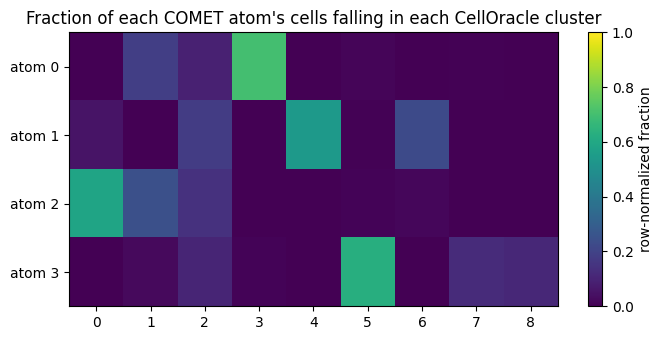

Plurality CellOracle cluster per COMET atom:
COMET_atom
0    3
1    4
2    0
3    5
dtype: int64


In [7]:
contingency = pd.crosstab(
    pd.Series(comet_cluster_labels, name="COMET_atom"),
    pd.Series(true_labels, name="CellOracle_cluster"),
)

fig, ax = plt.subplots(figsize=(7, 3.5))
row_norm = contingency.div(contingency.sum(axis=1), axis=0)
im = ax.imshow(row_norm.values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_yticks(range(len(row_norm.index))); ax.set_yticklabels([f"atom {i}" for i in row_norm.index])
ax.set_xticks(range(len(row_norm.columns))); ax.set_xticklabels(row_norm.columns)
ax.set_title("Fraction of each COMET atom's cells falling in each CellOracle cluster")
fig.colorbar(im, ax=ax, label="row-normalized fraction")
plt.tight_layout()
plt.show()

print("Plurality CellOracle cluster per COMET atom:")
print(contingency.idxmax(axis=1))

## Cell-level discrimination: does a cell's inferred GRN look like its own cluster's CellOracle GRN?

Same z-normalized nearest-cluster-match test as `compare_to_celloracle.ipynb`, scored against the filtered per-cluster CellOracle GRNs. This is the metric to trust most for a genuine cross-dataset comparison, since z-normalization removes the cluster-density bias that a shared prior would otherwise inject equally into every cluster's score.

In [8]:
N_SAMPLE = 300
N_SHUFFLE = 200
SEED = 0

rng = np.random.default_rng(SEED)
sample_idx = rng.choice(n_cells, size=min(N_SAMPLE, n_cells), replace=False)
print(f"Scoring {len(sample_idx)} cells against {N_CLUSTERS} CellOracle cluster GRNs")


def precompute_orders(grn_abs, eps=EPS):
    orders, mask = [], np.zeros((T, G), dtype=bool)
    for t in range(T):
        x = grn_abs[:, t]
        nz = np.flatnonzero(x > eps)
        orders.append(nz[np.argsort(x[nz])[::-1]])
        mask[t, nz] = True
    return orders, mask


cl_orders, cl_mask = {}, {}
for cl, mat in co_cluster_mats.items():
    cl_orders[cl], cl_mask[cl] = precompute_orders(np.abs(mat))


def mean_jaccard_to_cluster(cell_orders, cl, top_frac=TOP_FRAC):
    j = []
    for t in range(T):
        ox, oy = cell_orders[t], cl_orders[cl][t]
        if ox.size == 0 or oy.size == 0:
            continue
        overlap_nz = cl_mask[cl][t][ox].sum()
        union_nz = ox.size + oy.size - overlap_nz
        k = max(1, round(top_frac * union_nz))
        kx, ky = min(k, ox.size), min(k, oy.size)
        inter = np.intersect1d(ox[:kx], oy[:ky], assume_unique=True).size
        j.append(inter / (kx + ky - inter))
    return np.mean(j) if j else np.nan


assigned, J_rows = [], []
for i in sample_idx:
    cell_grn = np.abs(np.einsum("d,dgt->gt", weights[i], A_dict))
    cell_orders, _ = precompute_orders(cell_grn)
    J_rows.append([mean_jaccard_to_cluster(cell_orders, cl) for cl in cluster_names])
    assigned.append(str(true_labels[i]))

assigned = np.array(assigned)
J = np.array(J_rows)

Z = (J - np.nanmean(J, axis=0, keepdims=True)) / np.nanstd(J, axis=0, keepdims=True)
Z_filled = np.where(np.isnan(Z), -np.inf, Z)
predicted = np.array(cluster_names)[Z_filled.argmax(1)]

acc = (predicted == assigned).mean()
shuffle_acc = np.array([(predicted == rng.permutation(assigned)).mean() for _ in range(N_SHUFFLE)])
p_emp = (shuffle_acc >= acc).mean()

print(f"Accuracy (z-normalized nearest cluster): {acc:.3f}")
print(f"Shuffle null:                            {shuffle_acc.mean():.3f} +/- {shuffle_acc.std():.3f}")
print(f"Nominal chance (1/{N_CLUSTERS}):                      {1/N_CLUSTERS:.3f}")
print(f"Empirical p vs shuffle:                  "
      f"{'< %.4f' % (1/N_SHUFFLE) if p_emp == 0 else '%.4f' % p_emp}")

Scoring 300 cells against 9 CellOracle cluster GRNs


Accuracy (z-normalized nearest cluster): 0.277
Shuffle null:                            0.094 +/- 0.015
Nominal chance (1/9):                      0.111
Empirical p vs shuffle:                  < 0.0050


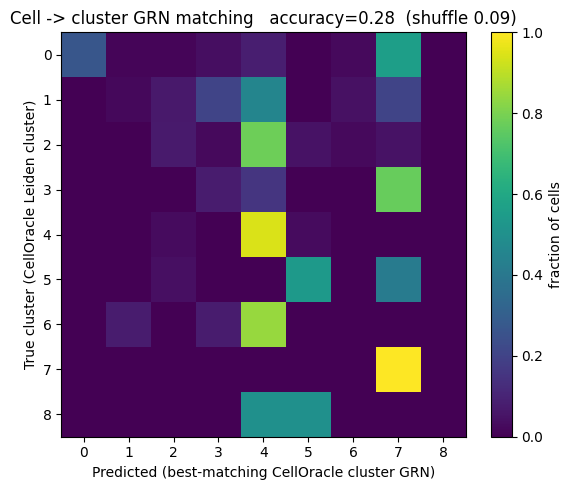

In [9]:
conf = pd.crosstab(pd.Series(assigned, name="true"), pd.Series(predicted, name="predicted"))
conf = conf.reindex(index=cluster_names, columns=cluster_names, fill_value=0)
conf_norm = conf.div(conf.sum(axis=1).replace(0, np.nan), axis=0)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(conf_norm.values, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(cluster_names))); ax.set_xticklabels(cluster_names)
ax.set_yticks(range(len(cluster_names))); ax.set_yticklabels(cluster_names)
ax.set_xlabel("Predicted (best-matching CellOracle cluster GRN)")
ax.set_ylabel("True cluster (CellOracle Leiden cluster)")
ax.set_title(f"Cell -> cluster GRN matching   accuracy={acc:.2f}  (shuffle {shuffle_acc.mean():.2f})")
fig.colorbar(im, ax=ax, label="fraction of cells", fraction=0.046)
plt.tight_layout()
plt.show()

## Hub-TF agreement, using CellOracle's real network-centrality score

Same construction as `compare_to_celloracle.ipynb`. This one wasn't available for the original `analysis7.ipynb` comparison (it used a hand-summed edge-weight proxy instead) — `get_network_score()` was run for the first time as part of the one-time prep step for this notebook.

Hub-TF agreement (Spearman), n=277 TFs with a CellOracle network score: rho=0.653, p=4.40e-35


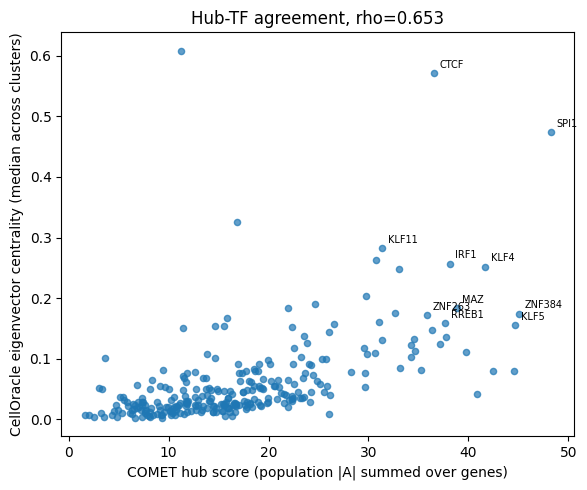

In [10]:
ns = network_scores.copy()
ns["gene"] = ns.index
co_hub = ns[ns["gene"].isin(A_tfs)].groupby("gene")["eigenvector_centrality"].median()
co_hub = co_hub.reindex(A_tfs)

comet_hub = np.abs(comet_global).sum(axis=0)
comet_hub = pd.Series(comet_hub, index=A_tfs)

both = pd.DataFrame({"comet_hub": comet_hub, "co_hub": co_hub}).dropna()
rho, pval = spearmanr(both["comet_hub"], both["co_hub"])
print(f"Hub-TF agreement (Spearman), n={len(both)} TFs with a CellOracle network score: "
      f"rho={rho:.3f}, p={pval:.2e}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(both["comet_hub"], both["co_hub"], s=20, alpha=0.7)
top10 = (both["comet_hub"].rank() + both["co_hub"].rank()).sort_values().index[-10:]
for g in top10:
    ax.annotate(g, (both.loc[g, "comet_hub"], both.loc[g, "co_hub"]), fontsize=7,
                xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("COMET hub score (population |A| summed over genes)")
ax.set_ylabel("CellOracle eigenvector centrality (median across clusters)")
ax.set_title(f"Hub-TF agreement, rho={rho:.3f}")
plt.tight_layout()
plt.show()